In [1]:
import agent as AG
import pandas as pd
import matplotlib.pyplot as plt
import os, re, sys, json, time, ast, operator, subprocess
AG.main()
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}

In [ ]:
ledger = AG.Ledger()

prompt = [{"role": "user", "content": "Come up with a name for a coffee shop near the university. Just the name, two words."}]
pd.DataFrame({f"temperature {t}": [AG.chat(ledger = ledger, messages = prompt, model = AG.MODELS["cheap"], tag = "temperature", temperature = t)["content"] for _ in range(5)]
        for t in (0.0, 1.8)})

,temperature 0.0,temperature 1.8
0,Campus Brew,Campus Brews
1,Campus Brew,Scholarly Sips
2,Campus Brew,Caffeine Corner
3,Campus Brew,Campus Brew
4,Campus Brew,Campus Brew.


In [3]:
ledger.table()


,,calls,prompt,completion,cost,seconds
tag,model,,,,,
temperature,gpt-4o-mini,10,270,26,0.00006,11.94


In [ ]:
ledger = AG.Ledger()
calls_before = len(ledger.calls)
try:
    result = AG.ask_structured(ledger, "What year was France founded?", AG.MODELS["cheap"], AG.Numeric)
except ValueError as e:
    result = e
print("вызовов потрачено:", len(ledger.calls) - calls_before, "| результат:", result)

вызовов потрачено: 1 | результат: final=843.0


In [ ]:
def normalize(text):
    text = re.sub(r"[^\w\s]", " ", str(text).lower().replace(",", ""))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())

def is_correct(task, answer):
    return normalize(task["answer"]) in normalize(answer)

def summary(config, model, n, correct, cost, steps, seconds=0.0):
    return {"config": config, "model": model.split("/")[-1], "n": n, "accuracy": round(correct / n, 2),
            "cost_per_task": round(cost / n, 5), "cost_per_correct": round(cost / correct, 5) if correct else float("inf"),
            "avg_steps": round(steps, 2), "avg_seconds": round(seconds, 1)}


In [3]:
def agent(question, model, tool_names, max_steps=8):
    messages = [{"role": "system", "content": AG.SYSTEM}, {"role": "user", "content": question}]
    before, started = ledger.total, time.perf_counter()
    answer, steps = AG.agent_loop(ledger, messages, model, tool_names, max_steps)
    return AG.Run(question, answer, steps, messages, ledger.total - before, time.perf_counter() - started)

def show_trace(run):
    for m in run.messages[1:]:
        calls = "; ".join(f"{c['function']['name']}{c['function']['arguments']}" for c in m.get("tool_calls") or [])
        text = " ".join((m.get("content") or "").split())[:180]
        print(f"{m['role']:9s}| {text} {calls}")
    print(f"шагов: {run.steps}, цена: {run.cost * 100:.3f} ¢, время: {run.seconds:.1f} c")

In [3]:
ledger = AG.Ledger()
run = agent("Сколько будет 17 * 23 + 5? Посчитай инструментом.", AG.MODELS["cheap"], ["calculator"])
show_trace(run)

user     | Сколько будет 17 * 23 + 5? Посчитай инструментом. 
assistant|  calculator{"expr":"17*23+5"}
tool     | 396 
assistant| Результат вычисления 17 * 23 + 5 равен 396. FINAL: 396 
шагов: 2, цена: 0.008 ¢, время: 3.1 c


Тесты на работоспособность инструментов по трем случаям: нормальный вход, пустой результат, ошибка

In [4]:
ledger = AG.Ledger()
assert AG.calculator("2+2") == "4"
assert AG.calculator("2**10") == "1024"
assert "ошибка" in AG.calculator("__import__('os')")
assert AG.web_search("Scott Derrickson").startswith("[Scott Derrickson]")
assert AG.web_search("qwxzv 1234567 nonsense") == "No data"
assert AG.python_exec("print(sum(range(10)))") == "45"
assert "ZeroDivisionError" in AG.python_exec("1/0")
assert "Код превысил 5 сек" in AG.python_exec("import time; time.sleep(10)")
q = AG.load_tasks('fresh.jsonl')[-2]['evidence']
assert AG.page_find('2026 in Brazil', 'Jorge').replace('.', '') == q
assert AG.page_find('2026 in Kizil', 'Jorge') == "no such page"
assert AG.page_find('2026 in Brazil', 'balalayka') == "keywords not found on the page"
"Все инструменты работают"

'Все инструменты работают'

In [5]:
def final_answer(text):
    m = re.search(r"FINAL:\s*(.+)", text or "")
    return m.group(1).strip() if m else (text or "").strip()

def run_tasks(tasks, model, tool_names, config):
    folder = AG.TRACES / config / model.split("/")[-1]
    folder.mkdir(parents=True, exist_ok=True)
    rows = []
    for task in tasks:
        try:
            run = agent(task["question"], model, tool_names)
        except Exception as e:
            run = AG.Run(task["question"], f"ошибка: {e}", 0, [])
        ok = is_correct(task, final_answer(run.answer))
        rows.append({"config": config, "model": model.split("/")[-1], "id": task["id"], "source": task["source"],
                     "correct": ok, "steps": run.steps, "tool_calls": sum(m["role"] == "tool" for m in run.messages),
                     "cost": run.cost, "seconds": round(run.seconds, 1), "answer": final_answer(run.answer)[:60], "gold": task["answer"]})
        (folder / f"{task['id']}.json").write_text(json.dumps({"task": task, "answer": run.answer, "correct": ok, "cost": run.cost,
                                                              "messages": run.messages}, ensure_ascii=False, indent=1), encoding="utf-8")
    return pd.DataFrame(rows)

def report(results):
    rows = [summary(config, model, len(df), int(df["correct"].sum()), df["cost"].sum(), df["steps"].mean(), df["seconds"].mean())
            for (config, model), df in results.groupby(["config", "model"])]
    return pd.DataFrame(rows).sort_values("cost_per_task").reset_index(drop=True)

def money_chart(table, path="img/money_quality.png"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, r in table.iterrows():
        color = COLORS["red"] if "каскад" in r["config"] else COLORS["amber"] if "sonnet" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100),
                    fontsize=8, xytext=(6, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена задачи, центы (логарифмическая шкала)")
    ax.set_ylabel("доля верных ответов, %")
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

def steps_chart(results):
    g = results.groupby("config").agg(steps=("steps", "mean"), tool_calls=("tool_calls", "mean"), seconds=("seconds", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    g[["steps", "tool_calls"]].plot.bar(ax=axes[0], color=[COLORS["violet"], COLORS["teal"]], rot=12)
    axes[0].set_ylabel("в среднем на задачу")
    g["seconds"].plot.bar(ax=axes[1], color=COLORS["amber"], rot=12)
    axes[1].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.grid(alpha=0.3, axis="y")
        ax.set_xlabel("")
    fig.tight_layout()
    return fig

CONFIGS = {"без инструментов": [], "поиск":["web_search"], "поиск и чтение": ["web_search", "page_find"],
           "все инструменты": ["calculator", "python_exec", "web_search", "page_find"]}


Весь набор скушает много времени и бюджета для сильной модели, поэтому я взял последние 40 вопросов (все свои + чутка стартового), так как опционально можно было бы создать свой набор из 40. VS свой набор из 40 вопрсов 

In [ ]:
qa = qa = AG.load_tasks("fresh.jsonl")[-40:]
frames = [run_tasks(qa, AG.MODELS["strong"],[], "без инструментов")]
frames += [run_tasks(qa, AG.MODELS["cheap"], CONFIGS[c], c) for c in ["без инструментов", "поиск", "поиск и чтение"]]
frames += [run_tasks(qa, AG.MODELS["mid"], CONFIGS[c], c) for c in ["все инструменты"]]

results = pd.concat(frames, ignore_index=True)
#results[["config", "model", "id", "correct", "steps", "tool_calls", "cost", "seconds", "answer", "gold"]][:5:10]

In [11]:
frames += [run_tasks(qa, AG.MODELS["mid"], CONFIGS[c], c) for c in ["все инструменты"]]

In [12]:
results = pd.concat(frames, ignore_index=True)
table = report(results)

In [13]:
table

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,без инструментов,gpt-4o-mini,40,0.03,0.00004,0.00176,1.00,2.3
1,поиск и чтение,gpt-4o-mini,40,0.28,0.00078,0.00285,5.22,27.3
2,поиск,gpt-4o-mini,40,0.28,0.00116,0.00423,6.62,38.6
3,без инструментов,claude-sonnet-4.6,40,0.17,0.00964,0.05508,1.00,10.3
4,все инструменты,claude-haiku-4.5,80,0.20,0.01090,0.05449,3.28,18.5


Немного ошибся в средней модели , вызвал ее без инструментов , а затем со всеми , поэтому 80 всего получилось. Времени исправить к текущему дд уже нет. Очевидно, чтобы улучшить точность, необходимо изучить трейсы, и лучше настроить все 

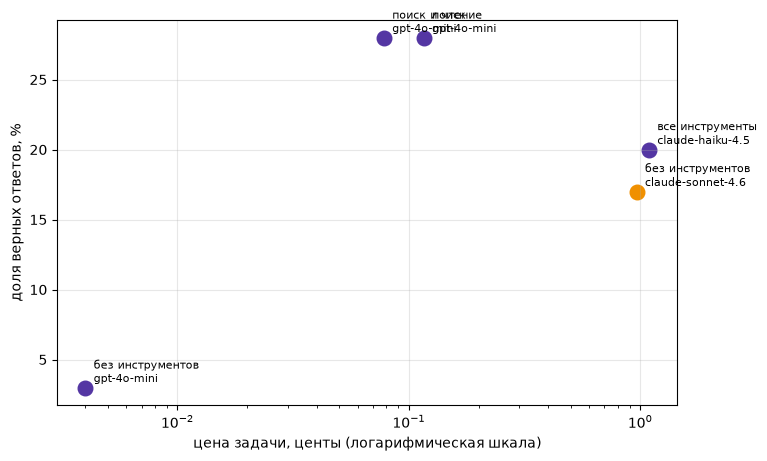

In [14]:
money_chart(table);

Два разобранных трейса : 
1) AI-agents\traces\поиск и чтение\gpt-4o-mini\fresh-124.json 
Поиск не нашел , так как Википедия выдала ошибку 409
2) AI-agents\traces\поиск и чтение\gpt-4o-mini\fresh-133.json
Ответ верный, но не прошел проверку.  April 1, 2026 , а в реальном ответе 1 April, скорее всего, дело в is_correct желательно его в будущем доработать 
